## 데이터셋 불러오기

In [1]:
import pandas as pd
import numpy as np

In [2]:
from sklearn import datasets
iris = datasets.load_iris()
iris.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [3]:
# DESCR 키를 이용하여 데이터셋 설명(Description) 출력
print(iris['DESCR'])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [4]:
# target 속성의 데이터셋 크기
print("데이터셋 크기:", iris['target'].shape) #꽃의 종류 - 정답

데이터셋 크기: (150,)


In [5]:
# target 속성의 데이터셋 내용
print("데이터셋 크기:", iris['target'])

데이터셋 크기: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


In [6]:
# data 속성의 데이터셋 크기
print("데이터셋 크기:", iris['data'].shape)

# data 속성의 데이터셋 내용(첫 7개 행을 추출)
print("데이터셋 크기:\n", iris['data'][:7, :])

데이터셋 크기: (150, 4)
데이터셋 크기:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]]


In [7]:
# data 속성을 판다스 df으로 변환
df = pd.DataFrame(iris['data'], columns=iris['feature_names'])
print("데이터프레임의 형태:", df.shape)
df.head(1)

데이터프레임의 형태: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


In [8]:
# 열(column) 이름을 간결하게 변경
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
df.head(1)

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2


In [9]:
# target 열 추가
df['Target'] = iris['target']
print('데이터셋의 크기: ', df.shape)
df.head(2)

데이터셋의 크기:  (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0


In [10]:
df.tail(2)

,sepal_length,sepal_width,petal_length,petal_width,Target
148,6.2,3.4,5.4,2.3,2
149,5.9,3.0,5.1,1.8,2


## 데이터 탐색(EDA)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   Target        150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [12]:
# 통계정보 요약
df.describe()

,sepal_length,sepal_width,petal_length,petal_width,Target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [13]:
# 결측값 확인
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
Target          0
dtype: int64

In [14]:
# 중복 데이터 확인
df.duplicated().sum()

np.int64(1)

In [15]:
# 중복 데이터 출력
df.loc[df.duplicated(), :]

,sepal_length,sepal_width,petal_length,petal_width,Target
142,5.8,2.7,5.1,1.9,2


In [16]:
#중복 데이터 모두 출력
df.loc[(df.sepal_length == 5.8)&(df.petal_width == 1.9), :]

,sepal_length,sepal_width,petal_length,petal_width,Target
101,5.8,2.7,5.1,1.9,2
142,5.8,2.7,5.1,1.9,2


In [17]:
# 중복 데이터 제거
df = df.drop_duplicates()
df.loc[(df.sepal_length == 5.8)&(df.petal_width == 1.9), :]

,sepal_length,sepal_width,petal_length,petal_width,Target
101,5.8,2.7,5.1,1.9,2


In [18]:
# 변수 간의 상관관계 분석
# 상관관계 수치 해석 - 구글링
# 꽃잎 깊이(petal_length	)와 꽃잎 너비(petal_width)가 품종과 높은 상관관계를 보임
df.corr()

,sepal_length,sepal_width,petal_length,petal_width,Target
sepal_length,1.000000,-0.118129,0.873738,0.820620,0.786971
sepal_width,-0.118129,1.000000,-0.426028,-0.362894,-0.422987
petal_length,0.873738,-0.426028,1.000000,0.962772,0.949402
petal_width,0.820620,-0.362894,0.962772,1.000000,0.956514
Target,0.786971,-0.422987,0.949402,0.956514,1.000000


# 변수 간의 상관관계 분석 결과
* 꽃잎 깊이(petal_length	)와 꽃잎 너비(petal_width)가 품종과 높은 상관관계를 보임
* 품종의 종류 분류에 중요한 변수라고 볼 수 있습니다.

In [19]:
# 시각화 라이브러리 설정
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(font_scale=1.2)

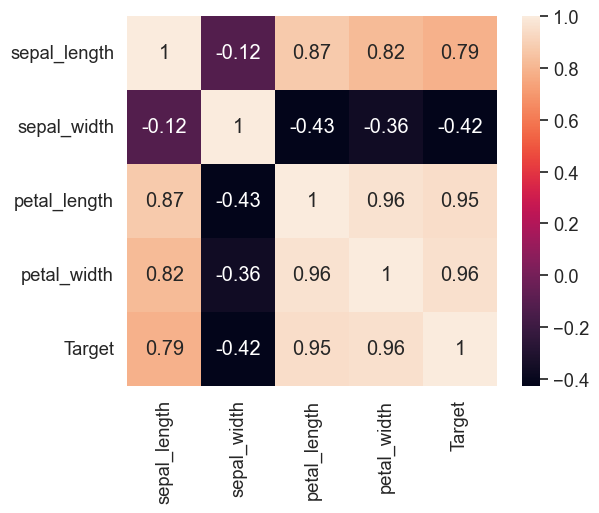

In [20]:
sns.heatmap(data = df.corr(), square = True, annot=True, cbar=True)
plt.show()

In [21]:
df['Target'].value_counts()

Target
0    50
1    50
2    49
Name: count, dtype: int64

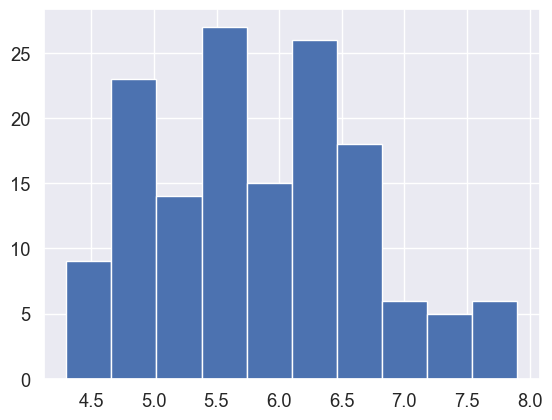

In [22]:
#sepal_Length 값의 분포
plt.hist(x='sepal_length', data = df)
plt.show()

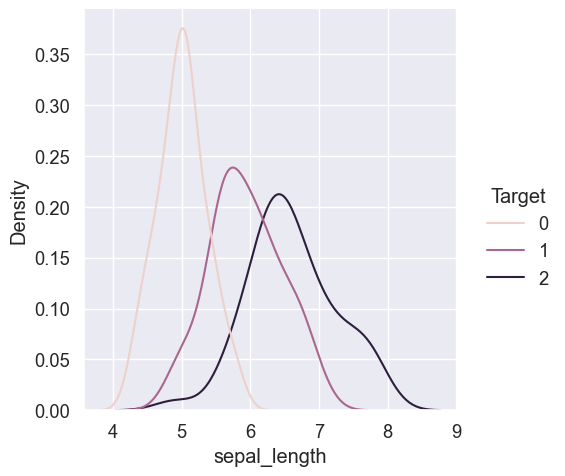

In [23]:
sns.displot(x = 'sepal_length', hue = 'Target', kind = 'kde', data = df)
plt.show()

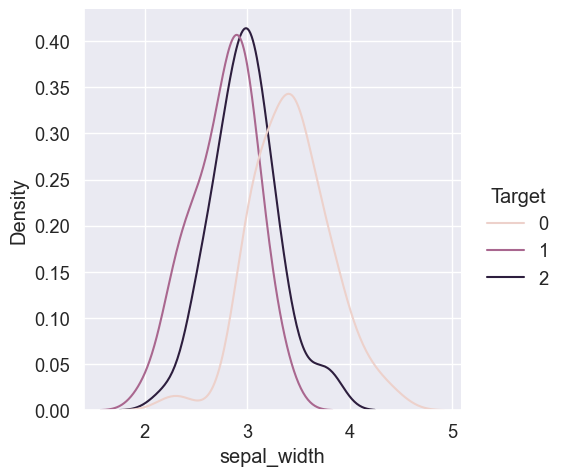

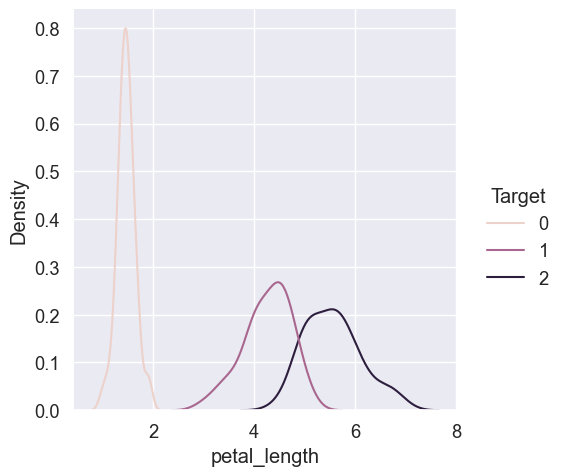

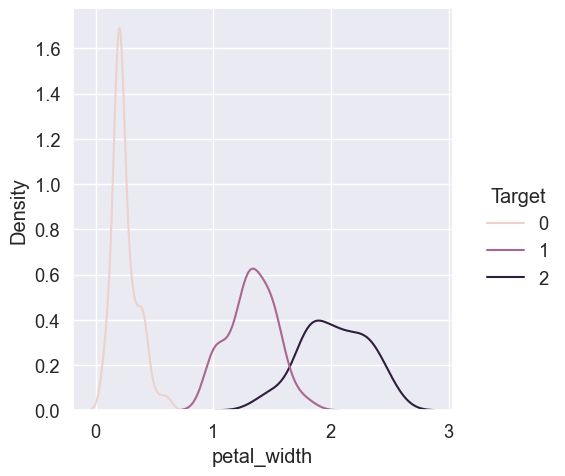

In [28]:
for col in ['sepal_width', 'petal_length', 'petal_width']:
    sns.displot(x=col, hue = 'Target', kind = 'kde', data = df)
plt.show()

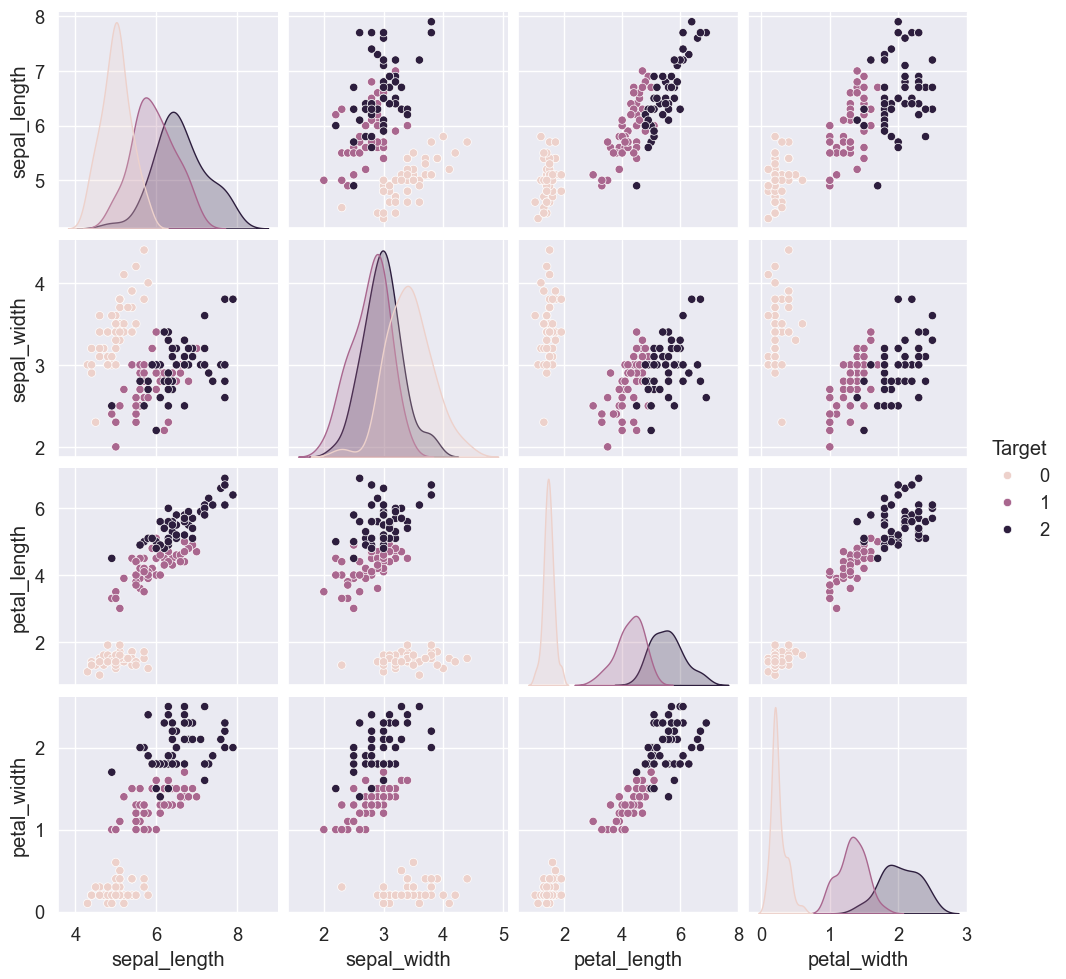

In [29]:
sns.pairplot(df, hue = 'Target', height = 2.5, diag_kind='kde')
plt.show()

##  Baseline 모델 학습
* 학습용 데이터와 데스트용 데이터셋 분리하기

In [34]:
from sklearn.model_selection import train_test_split

x_data = df.loc[:, 'sepal_length': 'petal_width']
y_data = df.loc[:, 'Target']

x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size = 0.2, shuffle = True, random_state = 20)

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(119, 4) (119,)
(30, 4) (30,)


## 모델 적용하기
* 1. knn

In [35]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train, y_train) #반드시 train 셋이 들어가야 합니다.

KNeighborsClassifier(n_neighbors=7)

In [39]:
# 예측
y_knn_pred = knn.predict(x_test)
print("예측값: ", y_knn_pred[:5])
print("실제값: ", y_test.values[:5])

예측값:  [0 1 1 2 1]
실제값:  [0 1 1 2 1]


In [42]:
# 성능 평가
from sklearn.metrics import accuracy_score
knn_acc = accuracy_score(y_test, y_knn_pred)
print("Accuracy: %.4f" % knn_acc)

Accuracy: 0.9667


* 2. SVM

In [43]:
# 모델 학습
from sklearn.svm import SVC
svc = SVC()
svc.fit(x_train, y_train)

SVC()

In [44]:
# 예측
y_svc_pred = svc.predict(x_test)
print("예측값: ", y_svc_pred[:5])

# 성능 평가
svc_acc = accuracy_score(y_test, y_svc_pred)
print("Accuracy: %.4f" % svc_acc)

예측값:  [0 1 1 2 1]
Accuracy: 1.0000


* 3. 로지스틱 회귀

In [45]:
from sklearn.linear_model import LogisticRegression
lrc = LogisticRegression()
lrc.fit(x_train, y_train)

LogisticRegression()

In [48]:
y_lrc_pred = lrc.predict(x_test)
print("예측값: ", y_lrc_pred[:5])

# 성능 평가
lrc_acc = accuracy_score(y_test, y_svc_pred)
print("Accuracy: %.4f" % lrc_acc)

예측값:  [0 1 1 2 1]
Accuracy: 1.0000


In [49]:
# 확률값 예측
y_lrc_prob = lrc.predict_proba(x_test)
y_lrc_prob

array([[9.83139644e-01, 1.68602982e-02, 5.74328653e-08],
       [4.60552773e-03, 8.41674941e-01, 1.53719531e-01],
       [1.03262735e-02, 9.20317645e-01, 6.93560819e-02],
       [2.57736150e-05, 5.16143112e-02, 9.48359915e-01],
       [2.39264643e-02, 9.52076488e-01, 2.39970475e-02],
       [2.94364729e-02, 9.25887384e-01, 4.46761433e-02],
       [4.77408546e-06, 1.77368555e-02, 9.82258370e-01],
       [9.80409858e-01, 1.95900287e-02, 1.13636818e-07],
       [1.22274817e-05, 6.68309694e-02, 9.33156803e-01],
       [9.75412463e-01, 2.45874729e-02, 6.39753136e-08],
       [2.73351290e-05, 2.70258428e-02, 9.72946822e-01],
       [1.70550599e-03, 7.50430287e-01, 2.47864207e-01],
       [7.54407262e-04, 4.92549607e-01, 5.06695986e-01],
       [9.84510035e-01, 1.54899369e-02, 2.81186375e-08],
       [9.76900112e-01, 2.30998239e-02, 6.38808351e-08],
       [1.28675599e-03, 2.60113725e-01, 7.38599519e-01],
       [9.91830511e-01, 8.16947786e-03, 1.11432069e-08],
       [4.13690162e-03, 8.61517

* 4. 의사결정나무

In [52]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier(max_depth=3, random_state=20) # max_depth=3 트리 깊이 조정
dtc.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=20)

In [53]:
y_dtc_pred = dtc.predict(x_test)
print("예측값: ", y_dtc_pred[:5])

# 성능 평가
dtc_acc = accuracy_score(y_test, y_dtc_pred)
print("Accuracy: %.4f" % dtc_acc)

예측값:  [0 1 1 2 1]
Accuracy: 0.9333


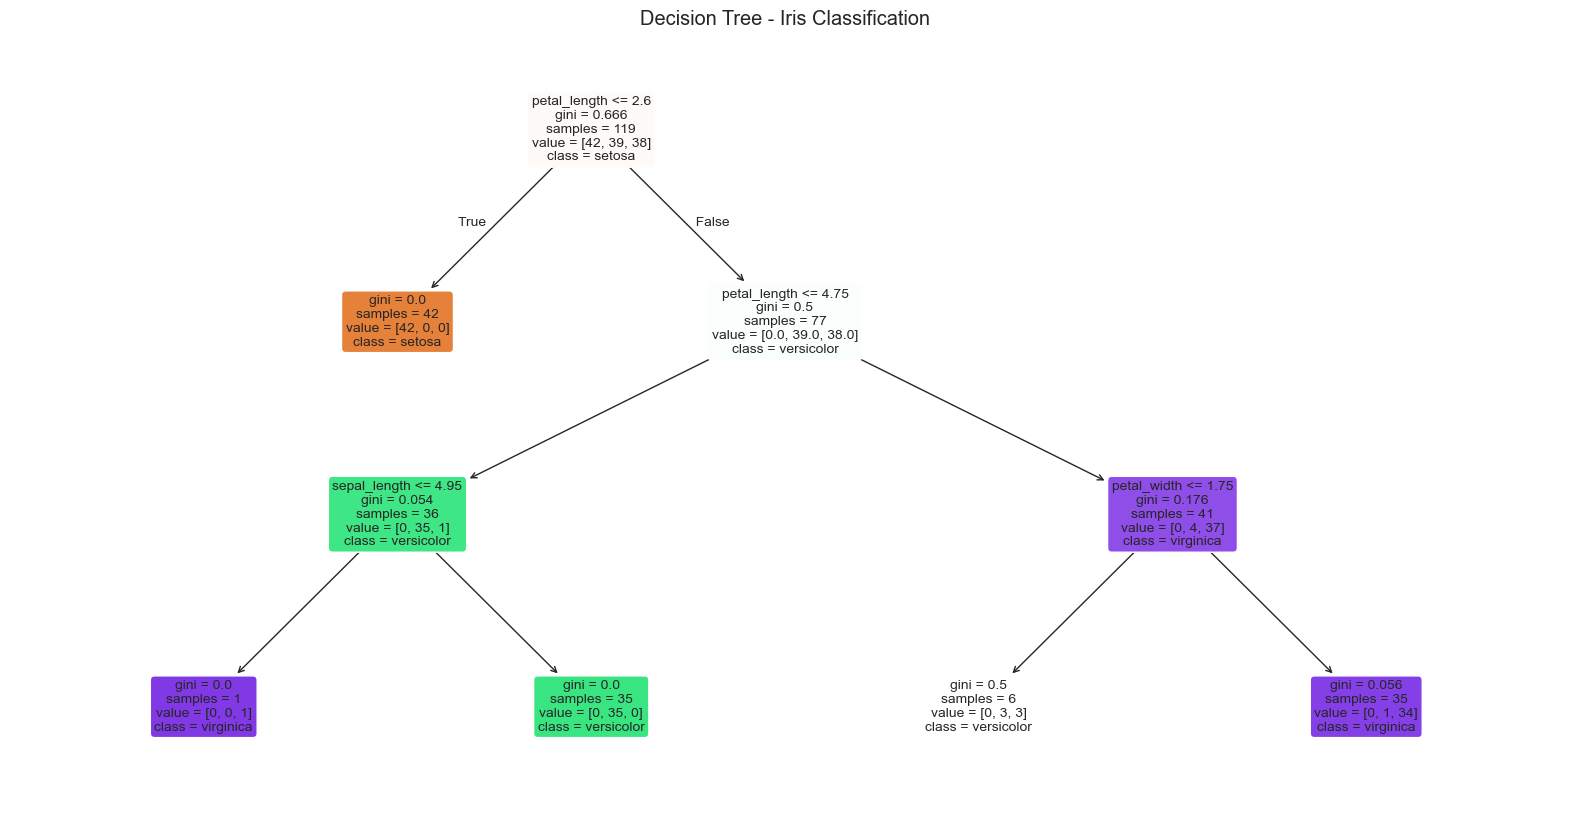

In [55]:
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 10))
plot_tree(dtc, feature_names=x_train.columns,
          class_names=[str(name) for name in iris.target_names],
          filled = True, rounded = True, fontsize = 10)
plt.title("Decision Tree - Iris Classification")
plt.show()

* 테스트 데이터에 대한 정확도를 비교해 보면 
* SVM과 로지스틱 회귀 100%로 가장 높은 성능을 보였습니다.
* KNN은 약 96.7%, 의사결정나무는 약 93.3%입니다.
* "SVM이 항상 가장 좋은 알고리즘이다"라고 결론 내리면 안됩니다.
* random_state나 데이터 분할 방법이 달라지면 결과도 달라질 수 있습니다.

## 문제
* [5.1, 3.5, 1.4, 0.2],
* [6.3, 3.3, 6.0, 2.5]
* 무슨 꽃인지 knn, dtc 예측해 보세요.

In [60]:
new_data = pd.DataFrame([[5.1, 3.5, 1.4, 0.2],
                         [6.3, 3.3, 6.0, 2.5]], columns=x_train.columns)

knn_pred = knn.predict(new_data)
knn_acc = accuracy_score(y_test, y_knn_pred)
print("knn 예측값: ", y_knn_pred[:5])
print("Accuracy: %.4f" % knn_acc)
print("knn 예측:", iris.target_names[knn_pred])

dtc_pred = dtc.predict(new_data)
dtc_acc = accuracy_score(y_test, y_dtc_pred)
print("dtc 예측값: ", y_dtc_pred[:5])
print("Accuracy: %.4f" % dtc_acc)
print("dtc 예측:", iris.target_names[dtc_pred])

knn 예측값:  [0 1 1 2 1]
Accuracy: 0.9667
knn 예측: ['setosa' 'virginica']
dtc 예측값:  [0 1 1 2 1]
Accuracy: 0.9333
dtc 예측: ['setosa' 'virginica']
